# LM9 Lab — Linear Systems, Inverses and Rank

Companion notebook to **From Calculus to Kelly, LM9**. It rebuilds the module's exhibits and computational examples from the sector closes, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | The sector closes with the repair rule; the four days (Exhibit 1); the sector sample of Section 8 |
| 2 | Both pictures of the 8–9 April system (Example 1, Exhibit 2, Exhibit 3) |
| 3 | Determinants: areas and angles (Example 2, Exhibit 5), cofactors with `Fraction` against `np.linalg.det` (Example 3) |
| 4 | Cramer's rule (Example 4) timed against `solve` for $n=2,\dots,9$, and its cost (Exhibit 6) |
| 5 | Elimination with and without row swaps (Example 5, Exhibit 7) against `solve` |
| 6 | Gauss–Jordan and the inverse (Exhibit 8); LM7's $\Sigma^{-1}$ (Example 6) |
| 7 | Rank and the number of solutions (Exhibit 10, Example 7, Example 8, Exhibit 9, Exhibit 11) |
| 8 | Perfect collinearity: the mix column (Example 9), the two 50/50 mixes (Exhibit 12), the third columns of the knowledge check, U28 and Electronic |
| 9 | Practice problems 4–11 and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds two files. `sectors_close_raw.csv` has the daily closes that FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, empty where a series has no close. `sectors_close_repairs.csv` lists the 561 closes that FinMind copied from another date or series, each with its official 13:30:00 value from `TaiwanStockEvery5SecondsIndex` (a paid dataset; the column is empty on FinMind's free plan). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** The hand-sized systems use percent returns $100(P_t/P_{t-1}-1)$ of 7–10 April 2025, rounded to 0.01, solved in exact rational arithmetic (`fractions.Fraction`). Section 8 uses daily simple returns on the Volume II sector sample: closes from 2008-12-01 to 2026-10-08, returns between consecutive TAIEX trading dates.

In [1]:
from pathlib import Path
from fractions import Fraction
from decimal import Decimal, ROUND_HALF_UP, ROUND_HALF_EVEN
import math
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def dec(x, k):
    # an exact rational rounded to k decimals, as text
    q = (Decimal(x.numerator) / Decimal(x.denominator)).quantize(Decimal(1).scaleb(-k), rounding=ROUND_HALF_EVEN)
    return format(q, "f")


def det_cof(m):
    # determinant by cofactor expansion along the first row (n! terms; exact for Fractions)
    n = len(m)
    if n == 1:
        return m[0][0]
    return sum((-1) ** j * m[0][j] * det_cof([row[:j] + row[j + 1:] for row in m[1:]]) for j in range(n))


def rref(m):
    # reduced row echelon form and pivot columns, exact
    a = [list(r) for r in m]
    rows, cols, piv, r = len(a), len(a[0]), [], 0
    for c in range(cols):
        k = next((i for i in range(r, rows) if a[i][c] != 0), None)
        if k is None:
            continue
        a[r], a[k] = a[k], a[r]
        a[r] = [v / a[r][c] for v in a[r]]
        for i in range(rows):
            if i != r and a[i][c] != 0:
                f = a[i][c]
                a[i] = [v - f * w for v, w in zip(a[i], a[r])]
        piv.append(c)
        r += 1
        if r == rows:
            break
    return a, piv


def rank_exact(m):
    return len(rref(m)[1])


def with_col(m, j, v):
    return [row[:j] + [vi] + row[j + 1:] for row, vi in zip(m, v)]


def cramer(m, b):
    d = det_cof(m)
    return [det_cof(with_col(m, j, b)) / d for j in range(len(m))]

## Part 1 — Data: the repair rule, the four days and the sector sample

FinMind serves some sector closes copied from another date or another series. The repair cell replaces each close listed in `sectors_close_repairs.csv` by its 13:30:00 value; a listed close without that value (FinMind's free plan) is dropped, never estimated. With every value present, the result equals the closes the module uses, cell for cell.

In [2]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
SERIES = raw.columns[1:]                         # TAIEX and the 30 sector ids
AGG = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
U28 = [c for c in SERIES if c not in ["TAIEX", *AGG]]
ELEC8 = ["Semiconductor", "ComputerPeripheralEquipment", "Optoelectronic", "CommunicationsInternet",
         "ElectronicPartsComponents", "ElectronicProductsDistribution", "InformationService", "OtherElectronic"]
closes = raw
for sid in rep["id"].unique().sort().to_list():
    fix = (rep.filter(pl.col("id") == pl.lit(sid))
              .select("date", pl.col("close_1330").alias("_fix"), pl.lit(True).alias("_listed")))
    closes = (closes.join(fix, on="date", how="left")
                    .with_columns(pl.when(pl.col("_listed")).then(pl.col("_fix")).otherwise(pl.col(sid)).alias(sid))
                    .drop("_fix", "_listed").sort("date"))
n_fixed = rep.filter(pl.col("close_1330").is_not_null()).height
in_u28 = rep.filter(pl.col("id").is_in(U28) & (pl.col("date") >= pl.lit("2008-12-01")))
in_sec8 = rep.filter(pl.col("id").is_in(["Electronic", *ELEC8, "FinancialInsurance"])
                     & (pl.col("date") >= pl.lit("2008-12-01")))
print("rule: each listed close is replaced by its 13:30:00 value; without that value it is dropped")
print(f"listed closes {rep.height}: replaced {n_fixed}, dropped {rep.height - n_fixed}")
print(f"in U28 from 2008-12-01: {in_u28.height} closes on {in_u28['date'].n_unique()} dates; "
      f"in Electronic, its eight sub-industries and FinancialInsurance: {in_sec8.height}")
print(f"{len(SERIES)} series, {closes.height} dates, {closes['date'][0]} -> {closes['date'][-1]}")

rule: each listed close is replaced by its 13:30:00 value; without that value it is dropped
listed closes 561: replaced 561, dropped 0
in U28 from 2008-12-01: 524 closes on 38 dates; in Electronic, its eight sub-industries and FinancialInsurance: 180
31 series, 4737 dates, 2007-07-02 -> 2026-10-08


In [3]:
# the four days: exact percent returns from the two-decimal closes, rounded to 0.01
DAYS = ["2025-04-07", "2025-04-08", "2025-04-09", "2025-04-10"]
COLS = ["TAIEX", "Semiconductor", "FinancialInsurance", "Food"]
win = closes.filter(pl.col("date").is_between(pl.lit("2025-04-02"), pl.lit("2025-04-10"))).select("date", *COLS)
assert win["date"].to_list() == ["2025-04-02", *DAYS]          # 3-4 April were holidays
assert rep.filter(pl.col("date").is_between(pl.lit("2025-04-02"), pl.lit("2025-04-10"))).height == 0
P = {c: [Fraction(str(round(v, 2))) for v in win[c].to_list()] for c in COLS}
R_exact = {c: [100 * (P[c][k + 1] / P[c][k] - 1) for k in range(4)] for c in COLS}


def round2(x):
    up = (Decimal(x.numerator) / Decimal(x.denominator)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP)
    assert up == (Decimal(x.numerator) / Decimal(x.denominator)).quantize(Decimal("0.01"), rounding=ROUND_HALF_EVEN)
    return Fraction(up)


R = {c: [round2(v) for v in R_exact[c]] for c in COLS}
MF = [[R["Semiconductor"][k], R["FinancialInsurance"][k], R["Food"][k]] for k in range(4)]   # rows: days
BF = R["TAIEX"]
days = pl.DataFrame({"session": DAYS, "TAIEX b_i": [float(v) for v in BF],
                     "Semiconductor": [float(r[0]) for r in MF], "FinancialInsurance": [float(r[1]) for r in MF],
                     "Food": [float(r[2]) for r in MF]})
ties = sorted((abs(100 * v - math.floor(100 * v) - Fraction(1, 2)) / 100, c, d, v)
              for c in COLS for d, v in zip(DAYS, R_exact[c]))
print(f"TAIEX 7 April before rounding: {dec(R_exact['TAIEX'][0], 6)}%")
print(f"closest to a rounding tie: {ties[0][1]} {ties[0][2]} at {dec(ties[0][3], 6)}, {dec(ties[0][0], 6)} away")
days   # Exhibit 1

TAIEX 7 April before rounding: -9.699731%
closest to a rounding tie: Food 2025-04-08 at 3.774862, 0.000138 away


session,TAIEX b_i,Semiconductor,FinancialInsurance,Food
str,f64,f64,f64,f64
"""2025-04-07""",-9.7,-9.95,-9.89,-8.66
"""2025-04-08""",-4.02,-3.99,0.53,3.77
"""2025-04-09""",-5.79,-4.47,-5.61,-4.17
"""2025-04-10""",9.25,9.91,8.36,5.72


In [4]:
# the sector sample of Section 8: closes from 2008-12-01, returns between consecutive TAIEX trading dates
cs = closes.filter(pl.col("date") >= pl.lit("2008-12-01")).sort("date")
rets = cs.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in SERIES]).slice(1)
sample = rets.drop_nulls(subset=[*U28, "Electronic", "TAIEX"])
T = sample.height
print(f"sector sample: {cs.height} closes {cs['date'][0]} -> {cs['date'][-1]}; T = {T:,} returns, first {sample['date'][0]}")

sector sample: 4383 closes 2008-12-01 -> 2026-10-08; T = 4,382 returns, first 2008-12-02


## Part 2 — Two pictures of the 8–9 April system

Rows: each day is a line in the plane of the multiples $(x_1,x_2)$. Columns: $x_1\mathbf m_1+x_2\mathbf m_2$ must reach $\mathbf b$, equation (9.1).

E1: det = 24.753  x = ['1.035062', '0.207357']
    check: M x = ['-4.020000', '-5.790000']  b = [-4.02, -5.79]


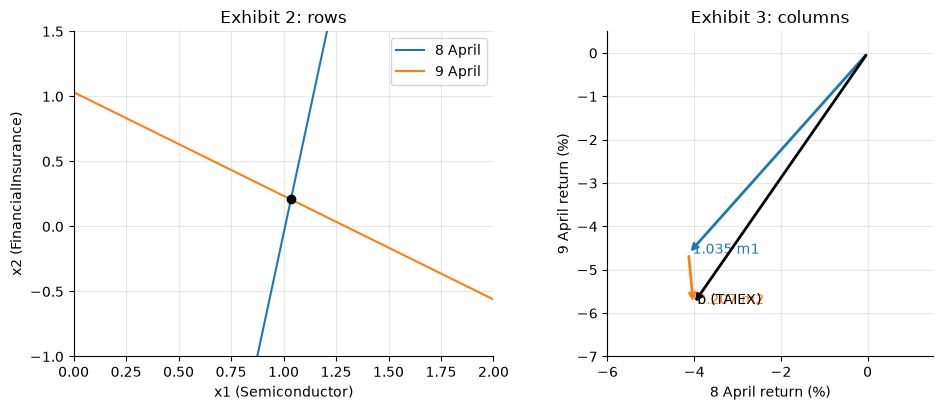

In [5]:
M1 = [MF[1][:2], MF[2][:2]]          # 8 and 9 April; Semiconductor, FinancialInsurance
b1 = BF[1:3]
x1 = cramer(M1, b1)
print("E1: det =", dec(det_cof(M1), 3), " x =", [dec(v, 6) for v in x1])
print("    check: M x =", [dec(sum(a * v for a, v in zip(row, x1)), 6) for row in M1], " b =", [float(v) for v in b1])

fig, (ax_r, ax_c) = plt.subplots(1, 2, figsize=(10, 4.2))
u = np.linspace(0, 2, 50)
for row, rhs, lab in zip(M1, b1, ("8 April", "9 April")):
    a, c, r = float(row[0]), float(row[1]), float(rhs)
    if abs(c) > abs(a):
        ax_r.plot(u, (r - a * u) / c, label=lab)
    else:
        v_ = np.linspace(-1, 1.5, 50)
        ax_r.plot((r - c * v_) / a, v_, label=lab)
ax_r.plot(float(x1[0]), float(x1[1]), "ko")
ax_r.set(xlim=(0, 2), ylim=(-1, 1.5), xlabel="x1 (Semiconductor)", ylabel="x2 (FinancialInsurance)",
         title="Exhibit 2: rows")
ax_r.legend()
m1, m2 = np.array([float(M1[0][0]), float(M1[1][0])]), np.array([float(M1[0][1]), float(M1[1][1])])
p = float(x1[0]) * m1
for start, vec, col, lab in ((np.zeros(2), p, "C0", "1.035 m1"), (p, float(x1[1]) * m2, "C1", "0.207 m2"),
                             (np.zeros(2), np.array([float(v) for v in b1]), "k", "b (TAIEX)")):
    ax_c.annotate("", xy=start + vec, xytext=start, arrowprops=dict(arrowstyle="->", color=col, lw=2))
    ax_c.text(*(start + vec), " " + lab, color=col)
ax_c.set(xlim=(-6, 1.5), ylim=(-7, 0.5), aspect="equal", xlabel="8 April return (%)", ylabel="9 April return (%)",
         title="Exhibit 3: columns")
plt.tight_layout()
plt.show()

## Part 3 — Determinants: area, angle and the cofactor expansion

The $2\times2$ determinant is the signed area spanned by the columns, (9.2): $\lvert\det M\rvert=\lVert\mathbf m_1\rVert\,\lVert\mathbf m_2\rVert\sin\theta$.

In [6]:
def area_angle(m):
    c1 = np.array([float(m[0][0]), float(m[1][0])])
    c2 = np.array([float(m[0][1]), float(m[1][1])])
    n1, n2 = np.linalg.norm(c1), np.linalg.norm(c2)
    return n1, n2, math.degrees(math.acos(c1 @ c2 / (n1 * n2)))


M2 = [[MF[0][0], MF[0][2]], [MF[2][0], MF[2][2]]]   # 7 and 9 April; Semiconductor, Food
b2 = [BF[0], BF[2]]
for name, m, b in (("8, 9 April: Semiconductor, FinancialInsurance", M1, b1), ("7, 9 April: Semiconductor, Food", M2, b2)):
    n1, n2, th = area_angle(m)
    d = det_cof(m)
    dot = m[0][0] * m[0][1] + m[1][0] * m[1][1]       # positive: the angle is acute, so sin(theta) picks theta
    print(f"{name}: det {dec(d, 4)}; |m1| {n1:.6f}, |m2| {n2:.6f}, product {n1 * n2:.4f}; "
          f"sin(theta) {float(d) / (n1 * n2):.4f}; dot product {dec(dot, 4)}; theta {th:.2f} deg; "
          f"x = {[dec(v, 5) for v in cramer(m, b)]}")
print("ratio of the areas:", round(float(det_cof(M1) / det_cof(M2)), 2), "(about nine)")

8, 9 April: Semiconductor, FinancialInsurance: det 24.7530; |m1| 5.991744, |m2| 5.634980, product 33.7634; sin(theta) 0.7331; dot product 22.9620; theta 47.15 deg; x = ['1.03506', '0.20736']
7, 9 April: Semiconductor, Food: det 2.7813; |m1| 10.907951, |m2| 9.611686, product 104.8438; sin(theta) 0.0265; dot product 104.8069; theta 1.52 deg; x = ['-3.48485', '5.12404']
ratio of the areas: 8.9 (about nine)


In [7]:
# Example 3: the 7-9 April system, cofactors with exact fractions against floating point
M3, b3 = MF[:3], BF[:3]
minors = [det_cof([row[:j] + row[j + 1:] for row in M3[1:]]) for j in range(3)]
terms = [(-1) ** j * M3[0][j] * minors[j] for j in range(3)]
D3 = det_cof(M3)
print("minors:", [dec(v, 4) for v in minors], " terms:", [dec(t, 6) for t in terms])
print("det M exact:", dec(D3, 6), "=", D3)
print("np.linalg.det:", repr(np.linalg.det(np.array(M3, dtype=float))))

minors: ['18.9396', '33.4902', '24.7530']  terms: ['-188.449020', '331.218078', '-214.360980']
det M exact: -71.591922 = -35795961/500000
np.linalg.det: np.float64(-71.591922)


## Part 4 — Cramer's rule and its cost

Cramer's rule (9.4) with cofactor expansions takes $(n+1)!$ terms, each a product of $n$ entries and so $n-1$ multiplications; elimination takes about $\tfrac23n^3$ operations. The timing uses real returns: the first $n$ sectors of U28 on the last $n$ days of the sample. Times depend on the machine; the counts do not.

In [8]:
x3 = cramer(M3, b3)
print("Example 4: numerators", [dec(det_cof(with_col(M3, j, b3)), 6) for j in range(3)])
print("               x =", [dec(v, 6) for v in x3], " sum", dec(sum(x3), 3))

rows = []
X_pct = sample.select(U28).to_numpy() * 100
for n in range(2, 10):
    m = X_pct[-n:, :n].tolist()
    b = sample["TAIEX"].to_numpy()[-n:] * 100
    t0 = time.perf_counter()
    xc = cramer(m, b.tolist())
    t1 = time.perf_counter()
    xs = np.linalg.solve(np.array(m), b)
    t2 = time.perf_counter()
    rows.append({"n": n, "(n+1)! terms": math.factorial(n + 1), "multiplications (n+1)!(n-1)": math.factorial(n + 1) * (n - 1),
                 "2n^3/3 operations": round(2 * n**3 / 3, 1),
                 "Cramer seconds": t1 - t0, "solve seconds": t2 - t1, "max |difference|": float(np.abs(np.array(xc) - xs).max())})
pl.DataFrame(rows)   # Exhibit 6: the counts; the times are this machine's

Example 4: numerators ['-23.919201', '-103.581657', '65.586258']
               x = ['0.334105', '1.446834', '-0.916113']  sum 0.865


n,(n+1)! terms,multiplications (n+1)!(n-1),2n^3/3 operations,Cramer seconds,solve seconds,max |difference|
i64,i64,i64,f64,f64,f64,f64
2,6,6,5.3,0.000015,0.000051,0.0
3,24,48,18.0,0.000021,0.000013,2.2204e-16
4,120,360,42.7,0.000075,0.000009,9.9920e-16
5,720,2880,83.3,0.000411,0.000009,8.8818e-16
6,5040,25200,144.0,0.002802,0.000058,4.4409e-16
7,40320,241920,228.7,0.021721,0.000067,1.5543e-15
8,362880,2540160,341.3,0.196451,0.000076,1.1102e-15
9,3628800,29030400,486.0,2.04525,0.000083,1.7764e-15


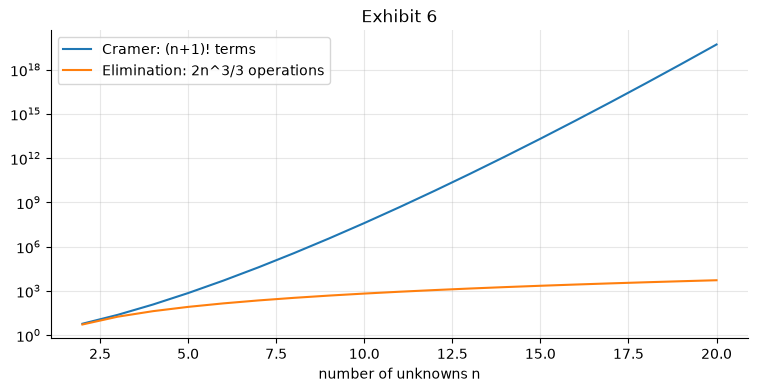

n = 20: 21! = 51,090,942,171,709,440,000 terms against 5,333 operations
n = 4: 120 products of four entries; 360 multiplications formed one by one, 200 in nested expansions


In [9]:
ns = np.arange(2, 21)
plt.semilogy(ns, [math.factorial(n + 1) for n in ns], label="Cramer: (n+1)! terms")
plt.semilogy(ns, 2 * ns**3 / 3, label="Elimination: 2n^3/3 operations")
plt.xlabel("number of unknowns n"); plt.title("Exhibit 6"); plt.legend(); plt.show()
print(f"n = 20: 21! = {math.factorial(21):,} terms against {2 * 20**3 / 3:,.0f} operations")


def nested(n):
    # multiplications of a nested cofactor expansion, which reuses the minors' values
    return 0 if n == 1 else n * (nested(n - 1) + 1)


print(f"n = 4: {5 * math.factorial(4)} products of four entries; {5 * math.factorial(4) * 3} multiplications "
      f"formed one by one, {5 * nested(4)} in nested expansions")

## Part 5 — Gaussian elimination, with and without row swaps

Each step subtracts $\ell_{ik}$ times the pivot row; partial pivoting first swaps up the row whose entry in the pivot column is largest in absolute value.

In [10]:
def eliminate(m, b, pivoting):
    a = [list(r) + [bi] for r, bi in zip(m, b)]
    n = len(a)
    steps, swaps = [], []
    for k in range(n - 1):
        if pivoting:
            p = max(range(k, n), key=lambda i: abs(a[i][k]))
            if p != k:
                a[k], a[p] = a[p], a[k]
                swaps.append((k + 1, p + 1))
        for i in range(k + 1, n):
            ell = a[i][k] / a[k][k]
            a[i] = [v - ell * w for v, w in zip(a[i], a[k])]
            steps.append({"step": k + 1, "row": i + 1, "multiplier": dec(ell, 6),
                          "new row": " ".join(dec(v, 6) for v in a[i])})
    piv = [a[k][k] for k in range(n)]
    x = [Fraction(0)] * n
    for i in reversed(range(n)):
        x[i] = (a[i][n] - sum(a[i][j] * x[j] for j in range(i + 1, n))) / a[i][i]
    return steps, swaps, piv, x


steps, swaps, piv, xg = eliminate(M3, b3, pivoting=False)
print("Example 5: swaps", swaps, " pivots", [dec(v, 6) for v in piv], " x", [dec(v, 6) for v in xg])
print("product of the pivots:", dec(piv[0] * piv[1] * piv[2], 6))
print("np.linalg.solve:", np.linalg.solve(np.array(M3, dtype=float), np.array(b3, dtype=float)).round(6))
# the printed six-decimal entries move the last digit: l32 and the back substitution from them
F = Fraction
print("l32: exact", steps[-1]["multiplier"], "; from the rounded entries", dec(F("-1.166955") / F("4.495940"), 6))
x2_r = (F("-0.130251") - F("7.242704") * F("-0.916113")) / F("4.495940")
x1_r = (F("-9.70") + F("9.89") * F("1.446834") + F("8.66") * F("-0.916113")) / F("-9.95")
print("x2, x1 from the rounded entries and the printed x3, x2:", dec(x2_r, 6), dec(x1_r, 6))
pl.DataFrame(steps)   # Exhibit 7

Example 5: swaps []  pivots ['-9.950000', '4.495940', '1.600370']  x ['0.334105', '1.446834', '-0.916113']
product of the pivots: -71.591922
np.linalg.solve: [ 0.334105  1.446834 -0.916113]
l32: exact -0.259557 ; from the rounded entries -0.259558
x2, x1 from the rounded entries and the printed x3, x2: 1.446835 0.334106


step,row,multiplier,new row
i64,i64,str,str
1,2,"""0.401005""","""0.000000 4.495940 7.242704 -0.130251"""
1,3,"""0.449246""","""0.000000 -1.166955 -0.279528 -1.432312"""
2,3,"""-0.259557""","""0.000000 0.000000 1.600370 -1.466119"""


## Part 6 — Gauss–Jordan elimination and the inverse

Row-reducing $[M\mid I_3]$ to $[I_3\mid M^{-1}]$ solves the three systems $M\mathbf k_j=\mathbf e_j$ at once. Column $j$ of $M^{-1}$ is the change in the mix per point of TAIEX's return on day $j$.

pivot columns: [0, 1, 2]
   ['-0.264549', '-0.102544', '0.456693']
   ['0.467793', '-0.038849', '-1.006607']
   ['-0.345751', '0.162186', '0.624855']


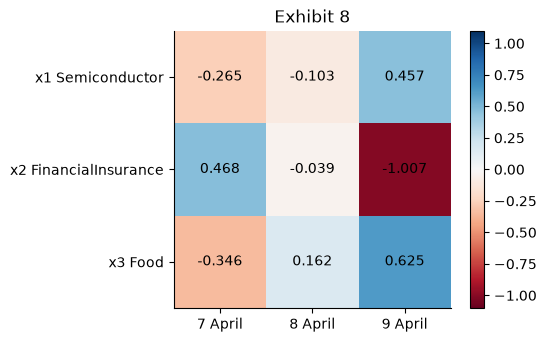

x = M^-1 b: ['0.334105', '1.446834', '-0.916113']


In [11]:
aug = [list(r) + [Fraction(int(i == j)) for j in range(3)] for i, r in enumerate(M3)]
red, pivcols = rref(aug)
Minv = [r[3:] for r in red]
print("pivot columns:", pivcols)
for r in Minv:
    print("  ", [dec(v, 6) for v in r])
fig, ax = plt.subplots(figsize=(5, 3.6))
im = ax.imshow(np.array(Minv, dtype=float), cmap="RdBu", vmin=-1.1, vmax=1.1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{float(Minv[i][j]):.3f}", ha="center", va="center")
ax.set_xticks(range(3), ["7 April", "8 April", "9 April"])
ax.set_yticks(range(3), ["x1 Semiconductor", "x2 FinancialInsurance", "x3 Food"])
ax.grid(False); ax.set_title("Exhibit 8"); plt.colorbar(im); plt.show()
print("x = M^-1 b:", [dec(sum(a * v for a, v in zip(r, b3)), 6) for r in Minv])

In [12]:
# Example 6: LM7's covariance matrix and excess returns, as LM7 prints them
S = [[Fraction("0.040425"), Fraction("-0.002866")], [Fraction("-0.002866"), Fraction("0.018214")]]
e = [Fraction("0.22751"), Fraction("-0.02547")]
dS = det_cof(S)
Sinv = [[S[1][1] / dS, -S[0][1] / dS], [-S[1][0] / dS, S[0][0] / dS]]     # formula (9.5)
f_star = [sum(a * v for a, v in zip(r, e)) for r in Sinv]
print("det Sigma =", float(dS), " Sigma^-1 =", [[dec(v, 4) for v in r] for r in Sinv])
print("Kelly fractions =", [dec(v, 4) for v in f_star])
print("np.linalg.inv:", np.linalg.inv(np.array(S, dtype=float)).round(4).tolist())

det Sigma = 0.000728086994  Sigma^-1 = [['25.0162', '3.9363'], ['3.9363', '55.5222']]
Kelly fractions = ['5.5912', '-0.5186']
np.linalg.inv: [[25.0162, 3.9363], [3.9363, 55.5222]]


## Part 7 — Rank and the number of solutions

Two days give a line of mixes, three days one mix, four days none ((9.7), (9.8)).

In [13]:
regimes = []
for name, rows_ in (("7-8 April", [0, 1]), ("7-9 April", [0, 1, 2]), ("7-10 April", [0, 1, 2, 3])):
    m = [MF[r] for r in rows_]
    mb = [MF[r] + [BF[r]] for r in rows_]
    regimes.append({"days": name, "equations x unknowns": f"{len(rows_)} x 3", "rank M": rank_exact(m),
                    "rank [M|b]": rank_exact(mb)})
red2, piv2 = rref([MF[r] + [BF[r]] for r in (0, 1)])
print(f"Example 7: x1 = {dec(red2[0][3], 6)} + {dec(-red2[0][2], 6)} x3,  x2 = {dec(red2[1][3], 6)} - {dec(red2[1][2], 6)} x3;"
      f"  x_h = ({dec(-red2[0][2], 6)}, {dec(-red2[1][2], 6)}, 1)")
print("Example 8: det [M|b] =", dec(det_cof([MF[r] + [BF[r]] for r in range(4)]), 6))
pl.DataFrame(regimes)   # Exhibit 10

Example 7: x1 = 1.003671 + 0.730877 x3,  x2 = -0.028971 - 1.610943 x3;  x_h = (0.730877, -1.610943, 1)
Example 8: det [M|b] = 65.603260


days,equations x unknowns,rank M,rank [M|b]
str,str,i64,i64
"""7-8 April""","""2 x 3""",2,2
"""7-9 April""","""3 x 3""",3,3
"""7-10 April""","""4 x 3""",3,4


In [14]:
TRI = {"7, 8, 9": [0, 1, 2], "7, 8, 10": [0, 1, 3], "7, 9, 10": [0, 2, 3], "8, 9, 10": [1, 2, 3]}
tri = []
for name, rows_ in TRI.items():
    m, b = [MF[r] for r in rows_], [BF[r] for r in rows_]
    x = cramer(m, b)
    tri.append({"days (April)": name, "det": dec(det_cof(m), 6), "Semiconductor": float(x[0]),
                "FinancialInsurance": float(x[1]), "Food": float(x[2])})
tri = pl.DataFrame(tri)
pred = sum(a * v for a, v in zip(MF[3], x3))
print(f"FinancialInsurance's multiple from {tri['FinancialInsurance'].min():.3f} to {tri['FinancialInsurance'].max():.3f}")
row7 = np.array(MF[0], dtype=float)
cos7 = -row7.sum() / (np.linalg.norm(row7) * math.sqrt(3))
print(f"7 April: the sectors fell {-row7.max():.2f}% to {-row7.min():.2f}%; "
      f"their row lies {math.degrees(math.acos(cos7)):.1f} deg from (-1, -1, -1)")
print(f"7-9 April mix on 10 April: {dec(pred, 2)}% against TAIEX's {float(BF[3])}%")
tri   # Exhibit 11

FinancialInsurance's multiple from -1.479 to 2.069
7 April: the sectors fell 8.66% to 9.95%; their row lies 3.6 deg from (-1, -1, -1)
7-9 April mix on 10 April: 10.17% against TAIEX's 9.25%


days (April),det,Semiconductor,FinancialInsurance,Food
str,str,f64,f64,f64
"""7, 8, 9""","""-71.591922""",0.334105,1.446834,-0.916113
"""7, 8, 10""","""22.568247""",1.661657,-1.479253,0.900269
"""7, 9, 10""","""-29.587887""",0.106741,1.360696,-0.556509
"""8, 9, 10""","""49.300524""",-0.017926,2.069318,-1.376197


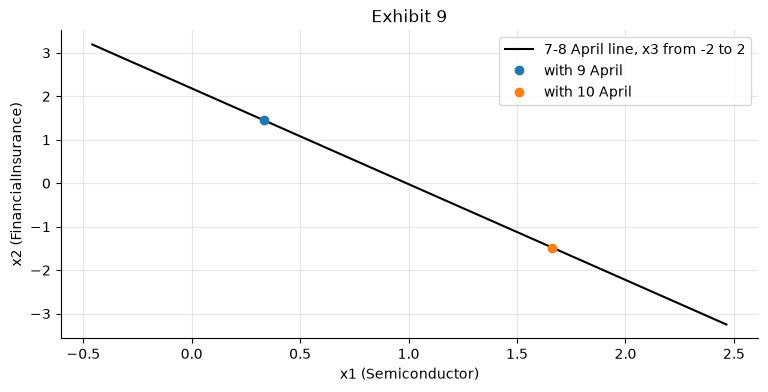

In [15]:
xp = np.array([float(red2[0][3]), float(red2[1][3])]); xh = np.array([float(-red2[0][2]), float(-red2[1][2])])
s_ = np.linspace(-2, 2, 50)
plt.plot(xp[0] + s_ * xh[0], xp[1] + s_ * xh[1], "k-", label="7-8 April line, x3 from -2 to 2")
for name, col in (("7, 8, 9", "C0"), ("7, 8, 10", "C1")):
    row = tri.filter(pl.col("days (April)") == pl.lit(name))
    plt.plot(row["Semiconductor"][0], row["FinancialInsurance"][0], "o", color=col, label=f"with {name.split(', ')[-1]} April")
plt.xlabel("x1 (Semiconductor)"); plt.ylabel("x2 (FinancialInsurance)"); plt.title("Exhibit 9"); plt.legend(); plt.show()

## Part 8 — Perfect collinearity

A return matrix has rank below its number of columns exactly when a fixed combination of its columns is 0 on every date (9.9).

In [16]:
# Example 9: replace Food by the daily rebalanced 50/50 mix of Semiconductor and FinancialInsurance
Mmix = [[r[0], r[1], (r[0] + r[1]) / 2] for r in M3]
print("mix column:", [float(r[2]) for r in Mmix], " exact ranks:", rank_exact(Mmix),
      rank_exact([r + [bi] for r, bi in zip(Mmix, b3)]))
Xm = np.array(Mmix, dtype=float)
print("np.linalg.det:", np.linalg.det(Xm), "(exactly 0 in exact arithmetic)")
try:
    xs = np.linalg.solve(Xm, np.array(b3, dtype=float))
    print("np.linalg.solve returned, largest |x_j| of order 10^%d, along x_h:" % round(math.log10(np.abs(xs).max())),
          (xs / xs[2]).round(6))
except np.linalg.LinAlgError as err:
    print("np.linalg.solve raised LinAlgError:", err)
print("np.linalg.matrix_rank:", np.linalg.matrix_rank(Xm))

mix column: [-9.92, -1.73, -5.04]  exact ranks: 2 3
np.linalg.det: 3.9732306333917235e-14 (exactly 0 in exact arithmetic)
np.linalg.solve returned, largest |x_j| of order 10^15, along x_h: [-0.5 -0.5  1. ]
np.linalg.matrix_rank: 2


matrix_rank, daily rebalanced: 2  buy-and-hold: 3
buy-and-hold weight in Semiconductor: 0.50 -> 0.858 on 2026-10-08; min 0.457 on 2011-08-04, max 0.883 on 2026-05-25
largest absolute daily gap between the two mixes' returns: 2.57 percentage points


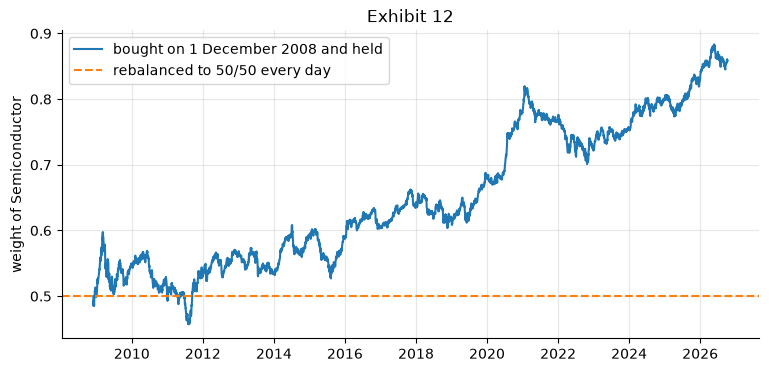

In [17]:
# the two 50/50 mixes on the sector sample
RS, RF = sample["Semiconductor"].to_numpy(), sample["FinancialInsurance"].to_numpy()
reb = 0.5 * RS + 0.5 * RF
PS, PF = cs["Semiconductor"].to_numpy(), cs["FinancialInsurance"].to_numpy()
V = 0.5 * PS / PS[0] + 0.5 * PF / PF[0]                      # buy-and-hold value from the 2008-12-01 close
w = 0.5 * (PS / PS[0]) / V                                  # its weight in Semiconductor
bh_all = cs.select("date").with_columns(pl.Series("V", V)).with_columns((pl.col("V") / pl.col("V").shift(1) - 1).alias("R_bh"))
bh = sample.select("date").join(bh_all.select("date", "R_bh"), on="date", how="left").sort("date")["R_bh"].to_numpy()
print("matrix_rank, daily rebalanced:", np.linalg.matrix_rank(np.column_stack([RS, RF, reb])),
      " buy-and-hold:", np.linalg.matrix_rank(np.column_stack([RS, RF, bh])))
dts = cs["date"].to_list()
iw_max, iw_min = int(np.nanargmax(w)), int(np.nanargmin(w))
print(f"buy-and-hold weight in Semiconductor: {w[0]:.2f} -> {w[-1]:.3f} on {dts[-1]}; "
      f"min {w[iw_min]:.3f} on {dts[iw_min]}, max {w[iw_max]:.3f} on {dts[iw_max]}")
print(f"largest absolute daily gap between the two mixes' returns: {np.nanmax(np.abs(reb - bh)) * 100:.2f} percentage points")
plt.plot(pl.Series(dts).str.to_date().to_list(), w, label="bought on 1 December 2008 and held")
plt.axhline(0.5, color="C1", ls="--", label="rebalanced to 50/50 every day")
plt.ylabel("weight of Semiconductor"); plt.title("Exhibit 12"); plt.legend(); plt.show()

In [18]:
# the knowledge check of Section 8: which third column makes the rank lower than 3?
V73 = 0.7 * PS / PS[0] + 0.3 * PF / PF[0]                    # a 70/30 mix bought at the 2008-12-01 close and held
bh73_all = cs.select("date").with_columns(pl.Series("V", V73)).with_columns((pl.col("V") / pl.col("V").shift(1) - 1).alias("R"))
bh73 = sample.select("date").join(bh73_all.select("date", "R"), on="date", how="left").sort("date")["R"].to_numpy()
for name, third in (("70/30 rebalanced daily", 0.7 * RS + 0.3 * RF), ("spread R_S - R_F", RS - RF), ("70/30 held", bh73)):
    print(f"{name}: matrix_rank {np.linalg.matrix_rank(np.column_stack([RS, RF, third]))}")

70/30 rebalanced daily: matrix_rank 2
spread R_S - R_F: matrix_rank 2
70/30 held: matrix_rank 3


In [19]:
XU = sample.select(U28).to_numpy()
XE = sample.select("Electronic", *ELEC8).to_numpy()
print("U28:", XU.shape, "matrix_rank", np.linalg.matrix_rank(XU))
print("Electronic + eight:", XE.shape, "matrix_rank", np.linalg.matrix_rank(XE))
print(f"correlation of Semiconductor with Electronic: {np.corrcoef(sample['Semiconductor'], sample['Electronic'])[0, 1]:.6f}")

U28: (4382, 28) matrix_rank 28
Electronic + eight: (4382, 9) matrix_rank 9
correlation of Semiconductor with Electronic: 0.952591


## Part 9 — Practice problems

**Problem 4.** Semiconductor and Food on 7 and 10 April, by Cramer's rule (9.4) and by the inverse formula (9.5).

In [20]:
M4 = [[MF[0][0], MF[0][2]], [MF[3][0], MF[3][2]]]
b4 = [BF[0], BF[3]]
d4 = det_cof(M4)
inv4 = [[M4[1][1] / d4, -M4[0][1] / d4], [-M4[1][0] / d4, M4[0][0] / d4]]
print("det", dec(d4, 4), " Cramer", [dec(v, 5) for v in cramer(M4, b4)],
      " (9.5)", [dec(sum(a * v for a, v in zip(r, b4)), 5) for r in inv4], " sum", dec(sum(cramer(M4, b4)), 3))

det 28.9066  Cramer ['0.85174', '0.14147']  (9.5) ['0.85174', '0.14147']  sum 0.993


**Problems 5 and 6.** Elimination with partial pivoting on 8–10 April; the determinant of 7, 8 and 10 April by cofactors and by pivots.

In [21]:
M5, b5 = MF[1:4], BF[1:4]
steps5, swaps5, piv5, x5 = eliminate(M5, b5, pivoting=True)
print("Problem 5: swaps", swaps5, " pivots", [dec(v, 6) for v in piv5], " x", [dec(v, 6) for v in x5],
      " det", dec(det_cof(M5), 6))
print(pl.DataFrame(steps5))
M6 = [MF[0], MF[1], MF[3]]
minors6 = [det_cof([row[:j] + row[j + 1:] for row in M6[1:]]) for j in range(3)]
steps6, _, piv6, _ = eliminate(M6, [BF[0], BF[1], BF[3]], pivoting=False)
print("Problem 6: minors", [dec(v, 4) for v in minors6], " det", dec(det_cof(M6), 6),
      " pivots", [dec(v, 6) for v in piv6], " product", dec(piv6[0] * piv6[1] * piv6[2], 6))

Problem 5: swaps [(1, 3), (2, 3)]  pivots ['9.910000', '3.895933', '1.276928']  x ['-0.017926', '2.069318', '-1.376197']  det 49.300524
shape: (3, 4)
┌──────┬─────┬────────────┬────────────────────────────────────────┐
│ step ┆ row ┆ multiplier ┆ new row                                │
│ ---  ┆ --- ┆ ---        ┆ ---                                    │
│ i64  ┆ i64 ┆ str        ┆ str                                    │
╞══════╪═════╪════════════╪════════════════════════════════════════╡
│ 1    ┆ 2   ┆ -0.451060  ┆ 0.000000 -1.839142 -1.589939 -1.617699 │
│ 1    ┆ 3   ┆ -0.402624  ┆ 0.000000 3.895933 6.073007 -0.295732   │
│ 2    ┆ 3   ┆ -0.472067  ┆ 0.000000 0.000000 1.276928 -1.757304   │
└──────┴─────┴────────────┴────────────────────────────────────────┘
Problem 6: minors ['-28.4856', '-60.1835', '-38.6087']  det 22.568247  pivots ['-9.950000', '4.495940', '-0.504492']  product 22.568247


**Problem 7.** The augmented matrix with the constant $a$: solvable only for $a=2$.

In [22]:
for a in (Fraction(2), Fraction(3)):
    aug7 = [[1, 2, 3, 1], [2, 4, 7, 3], [1, 2, 4, a]]
    red7, piv7 = rref([[Fraction(v) for v in r] for r in aug7])
    print(f"a = {a}: rank M = {rank_exact([[Fraction(v) for v in r[:3]] for r in aug7])}, rank [M|b] = {len(piv7)}, "
          f"reduced rows {[[str(v) for v in r] for r in red7]}")

a = 2: rank M = 2, rank [M|b] = 2, reduced rows [['1', '2', '0', '-2'], ['0', '0', '1', '1'], ['0', '0', '0', '0']]
a = 3: rank M = 2, rank [M|b] = 3, reduced rows [['1', '2', '0', '0'], ['0', '0', '1', '0'], ['0', '0', '0', '1']]


**Problem 8.** Three discount factors from three illustrative coupon bonds, by forward substitution.

In [23]:
coupons, prices = [2, 3, 4], [Fraction("100.50"), Fraction("102.55"), Fraction("106.25")]
Mb = [[Fraction(coupons[i] + (100 if j == i else 0)) if j <= i else Fraction(0) for j in range(3)] for i in range(3)]
v = []
for i in range(3):
    v.append((prices[i] - sum(Mb[i][j] * v[j] for j in range(i))) / Mb[i][i])
print("discount factors:", [dec(x, 6) for x in v])
print("annual-compounding spot rates z_t = v_t^(-1/t) - 1:", [f"{float(x) ** (-1 / (i + 1)) - 1:.4%}" for i, x in enumerate(v)])

discount factors: ['0.985294', '0.966933', '0.946549']
annual-compounding spot rates z_t = v_t^(-1/t) - 1: ['1.4925%', '1.6955%', '1.8480%']


**Problem 9.** TX and MTX on two illustrative days with TAIEX moves of −300 and +150 points.

In [24]:
moves = [Fraction(-300), Fraction(150)]
M9 = [[200 * dm, 50 * dm] for dm in moves]
print("M =", [[int(v) for v in r] for r in M9], " det =", det_cof(M9), " rank =", rank_exact(M9))
print("M x_h with x_h = (-1/4, 1):", [str(sum(a * v for a, v in zip(r, [Fraction(-1, 4), Fraction(1)]))) for r in M9])

M = [[-60000, -15000], [30000, 7500]]  det = 0  rank = 1
M x_h with x_h = (-1/4, 1): ['0', '0']


**Problem 10.** `solve` against `inv @ b`; `solve` on four days; `matrix_rank`.

In [25]:
Mf, bf = np.array(M3, dtype=float), np.array(b3, dtype=float)
print("largest |solve - inv @ b| =", np.abs(np.linalg.solve(Mf, bf) - np.linalg.inv(Mf) @ bf).max(), "(machine-dependent)")
four, b4d = np.array(MF, dtype=float), np.array(BF, dtype=float)
try:
    np.linalg.solve(four, b4d)
except np.linalg.LinAlgError as err:
    print("solve on four days: LinAlgError:", err)
print("matrix_rank of M and [M|b]:", np.linalg.matrix_rank(four), np.linalg.matrix_rank(np.column_stack([four, b4d])))

largest |solve - inv @ b| = 4.440892098500626e-16 (machine-dependent)
solve on four days: LinAlgError: Last 2 dimensions of the array must be square
matrix_rank of M and [M|b]: 3 4


**Problem 11.** The two 50/50 mixes on Section 8's sample: Part 8 printed the ranks (2 and 3), the final buy-and-hold weight and the largest absolute daily gap between the two mixes' returns, in percentage points.

**Without the repair files.** On FinMind's free plan the repair cell drops the 561 listed closes. No listed close falls on 2–10 April 2025, so Parts 2–7 and Problems 4–10 do not change. The sector sample loses the returns into and out of each dropped date: $T$ falls from 4,382 to 4,307, and the correlation of Semiconductor with Electronic moves from 0.952591 to 0.953091. The ranks, the buy-and-hold weights and the largest absolute daily gap stay as printed. The timings of Part 4 differ from machine to machine in any case.

### Extension: an exact fit for any $N$

Take $N$ sectors of U28 and exactly $N$ consecutive days, for $N=3,\dots,10$. Solve each square system and confirm that it fits TAIEX exactly: this is an in-sample fit, so it always succeeds when the determinant is not 0. How do the multiples change when you shift the window by one day or swap one sector? Then apply each mix to the following day and compare with TAIEX's return. Which choice of sectors and days would you have to defend before such a mix meant anything? LM12 fits many more days than sectors.

In [26]:
# starter: the first N sectors of U28 on the N days before the last day of the sample, percent returns
y_pct = sample["TAIEX"].to_numpy() * 100
for N in range(3, 11):
    m, b = X_pct[-N - 1:-1, :N], y_pct[-N - 1:-1]
    x = np.linalg.solve(m, b)
    print(N, "largest |multiple|", round(float(np.abs(x).max()), 2),
          " largest residual", f"{float(np.abs(m @ x - b).max()):.1e}")
# your code: apply each mix to the last day, X_pct[-1, :N] @ x against y_pct[-1]; vary the sectors and the days

3 largest |multiple| 3.16  largest residual 5.6e-16
4 largest |multiple| 3.02  largest residual 3.3e-16
5 largest |multiple| 2.53  largest residual 4.4e-16
6 largest |multiple| 2.82  largest residual 5.6e-16
7 largest |multiple| 1.77  largest residual 4.4e-16
8 largest |multiple| 0.92  largest residual 4.4e-16
9 largest |multiple| 0.47  largest residual 8.0e-16
10 largest |multiple| 0.65  largest residual 8.9e-16
